Customer Review Sentiment Analysis Using Naive Bayes

Dataset:
        review_id   product_category  rating  \
0  REV-2026-10001              Books       5   
1  REV-2026-10002              Books       1   
2  REV-2026-10003  Sports & Outdoors       2   
3  REV-2026-10004        Electronics       5   
4  REV-2026-10005             Beauty       5   

                                         review_text  review_length_chars  \
0  Great value for money. Excellent design and su...                   62   
1  Waste of money! Extremely poor durability and ...                   63   
2  Waste of money! Extremely poor durability and ...                   63   
3  Fantastic performance! Shipping was fast and c...                   74   
4  Best purchase I've made all year. Highly satis...                   74   

   word_count  helpful_votes verified_purchase sentiment  
0          11              1               Yes  Positive  
1           9              0               Yes  Negative  
2           9              0               Yes  Negative  
3  

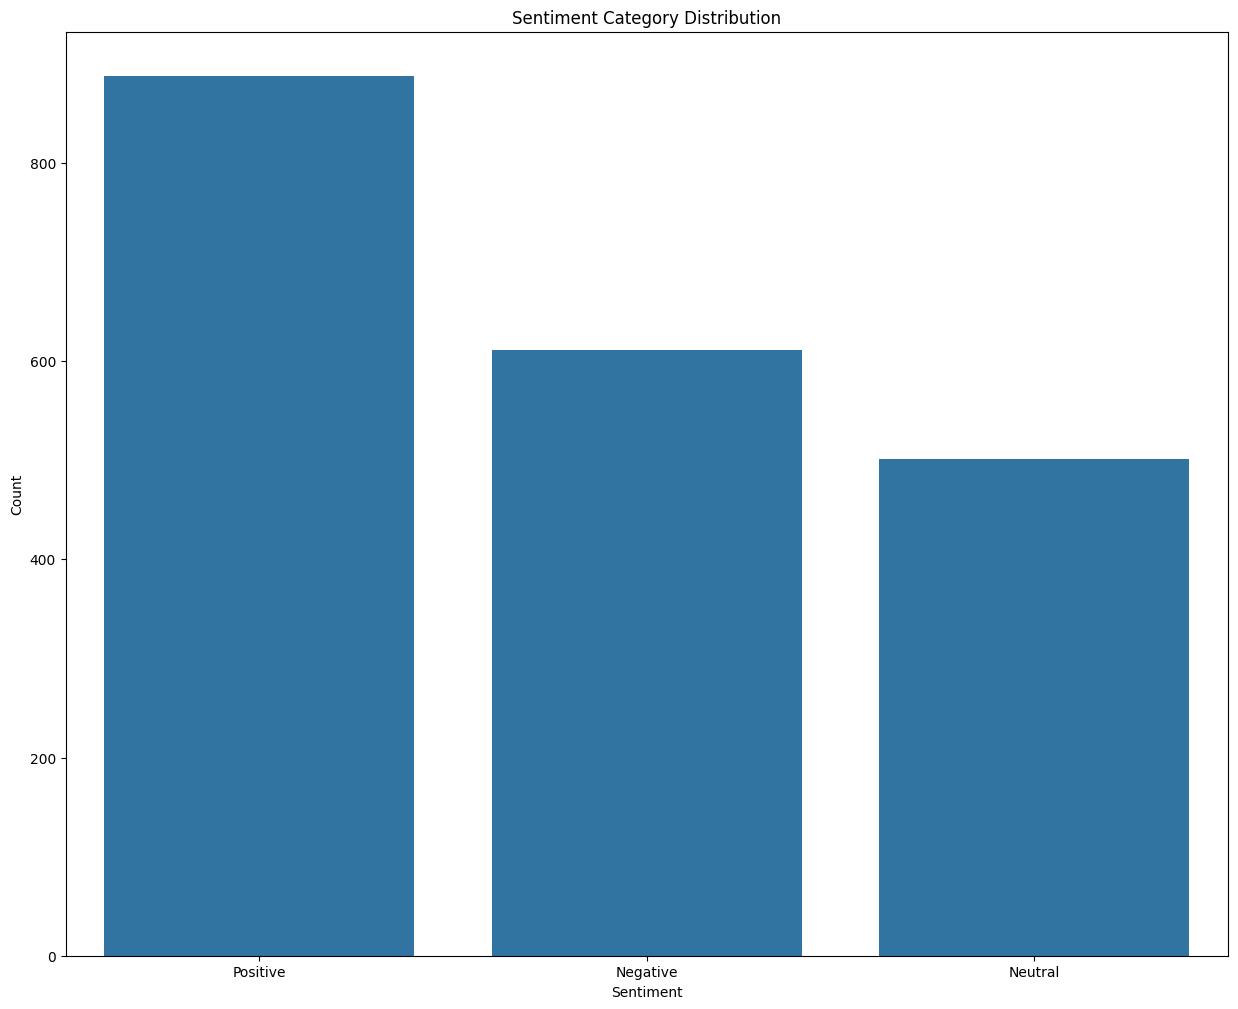


Training Samples: 1600
Testing Samples: 400

Original Text:
Impressive quality for the price point. Will definitely buy again.

Vectorized Shape:
(400, 123)

Vocabulary
['absolutely' 'after' 'again' 'all' 'and' 'arrived' 'at' 'average' 'basic'
 'best' 'bit' 'box' 'build' 'but' 'buy' 'call' 'cheap' 'confusing'
 'customer' 'damaged' 'days' 'decent' 'definitely' 'delivery'
 'description' 'design' 'disappointed' 'does' 'done' 'durability' 'easy'
 'everyone' 'exceeded' 'excellent' 'expectations' 'expected' 'experience'
 'extraordinary' 'extremely' 'fantastic' 'fast' 'features' 'feels' 'fine'
 'for' 'gets' 'good' 'great' 'helpful' 'highly' 'immediately' 'impressive'
 'improvement' 'instructions' 'is' 'it' 'item' 'job' 'just' 'longer'
 'love' 'made' 'match' 'material' 'met' 'money' 'my' 'not' 'notch'
 'nothing' 'of' 'okay' 'on' 'out' 'overall' 'perfectly' 'performance'
 'point' 'poor' 'premium' 'price' 'product' 'purchase' 'quality'
 'recommend' 'requirements' 'returning' 'right' 'room' 'sat

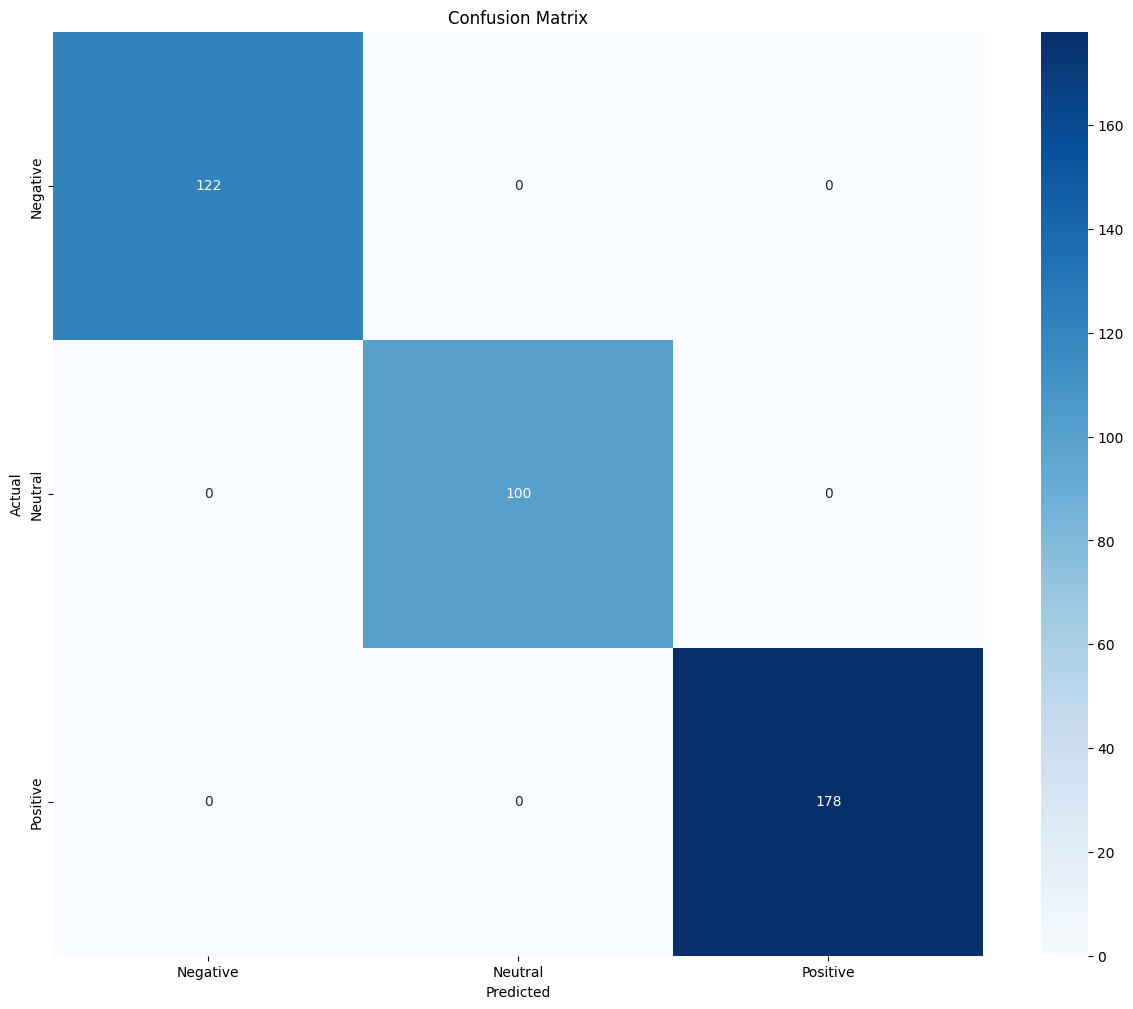


 ========= Classification Report ==========
              precision    recall  f1-score   support

    Negative       1.00      1.00      1.00       122
     Neutral       1.00      1.00      1.00       100
    Positive       1.00      1.00      1.00       178

    accuracy                           1.00       400
   macro avg       1.00      1.00      1.00       400
weighted avg       1.00      1.00      1.00       400


New Review Predictions:

Review: Waste of money! Extremely poor durability and slow performance.
Prediction: Negative

Review: Works perfectly right out of the box. Highly recommend to everyone!
Prediction: Positive

Review: Not Good enough
Prediction: Negative

Review: wast of money
Prediction: Negative

Naive Bayes Classes:
['Negative' 'Neutral' 'Positive']

Class Log Prior:
[-1.18539642 -1.38379748 -0.81249394]

Number of Features:
123

       PROJECT SUMMARY
Algorithm       : Multinomial Naive Bayes
Vectorizer      : CountVectorizer
Classes         : [np.str_('Ne

In [37]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.feature_extraction.text import CountVectorizer

from sklearn.metrics import(
    accuracy_score,
    confusion_matrix,
    classification_report
)


df = pd.read_csv("/content/customer_review_sentiment_dataset.csv")

print("Dataset:")
print(df.head())

print("\nDataset Information:")
df.info()

print("\n<issing Values:")
print(df.isnull().sum())

print("\nsentiment Distribution")
print(df["sentiment"].value_counts())

df.drop("review_id",axis=1,inplace=True)
# EDA

plt.figure(figsize=(15,12))

sns.countplot(
    data=df,
    x="sentiment"
)
plt.title("Sentiment Category Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Count")
plt.show()

X = df["review_text"]
y = df["sentiment"]

X_train,X_test, y_train,y_test = train_test_split(
    X,
    y,
    test_size = 0.2,
    random_state = 42,
    stratify=y
)

print("\nTraining Samples:", len(X_train))
print("Testing Samples:", len(X_test))

# TEXT → NUMERICAL FEATURES
vectorizer = CountVectorizer()

X_train_vectorized = vectorizer.fit_transform(X_train)
X_test_vectorized = vectorizer.transform(X_test)

print("\nOriginal Text:")
print(X_train.iloc[0])

print("\nVectorized Shape:")
print(X_test_vectorized.shape)

# CHECK VOCABULARY
print("\nVocabulary")
print(vectorizer.get_feature_names_out())

#CREATE NAIVE BAYES MODEL AND TRAIN

model = MultinomialNB()

model.fit(
    X_train_vectorized,
    y_train
)

# Predictions

y_pred = model.predict(X_test_vectorized)

print("\nActual Values:")
print(y_test.values)

print("\nPredicted Values:")
print(y_pred)


# Metrics

# ACCURACY
accuracy = accuracy_score(
    y_test,
    y_pred
)

print("\nAccuracy:", accuracy * 100)

#  CONFUSION MATRIX
cm = confusion_matrix(
    y_test,
    y_pred
)

print("\nConfusion Matrix")
print(cm)

plt.figure(figsize=(15,12))
sns.heatmap(
    cm,
    annot = True,
    fmt = "d",
    cmap ="Blues",
    xticklabels = model.classes_,
    yticklabels = model.classes_
)
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

#  CLASSIFICATION REPORT

print("\n ========= Classification Report ==========")
print(classification_report(
    y_test,
    y_pred
))

# New Prediction

new_review = [
    "Waste of money! Extremely poor durability and slow performance.",
    "Works perfectly right out of the box. Highly recommend to everyone!",
    "Not Good enough",
    "wast of money"
]

# Convert new text into numbers
new_review_vectorized = vectorizer.transform(new_review)

# Prediction
new_pred = model.predict(new_review_vectorized)

# Display results
print("\nNew Review Predictions:")

for review,prediction in zip(
    new_review,
    new_pred):

  print("\nReview:", review)
  print("Prediction:", prediction)


# MODEL INFORMATION
print("\nNaive Bayes Classes:")
print(model.classes_)

print("\nClass Log Prior:")
print(model.class_log_prior_)

print("\nNumber of Features:")
print(len(vectorizer.get_feature_names_out()))

print("\n======================================")
print("       PROJECT SUMMARY")
print("======================================")

print("Algorithm       : Multinomial Naive Bayes")
print("Vectorizer      : CountVectorizer")
print("Classes         :", list(model.classes_))
print("Accuracy        :", accuracy)
print("Training Samples:", len(X_train))
print("Testing Samples :", len(X_test))
print("======================================")